# Taxonomy coverage
How often do MBDef's papers define the bias types of two published media-bias taxonomies, Spinde et al. (2025) and Rodrigo-Ginés et al. (2024)? The figure shows the 11 types both cover, at the reporting, statement and language levels: a full dot means the taxonomy lists the type, a half dot that it covers it under another name. Each bar counts the distinct papers with a matching definition, seed papers in grey and closure papers in blue, labelled `total (seed, closure)`.

No model and no network are used.

## Load MBDef and MBDef-Gold
MBDef gives the counts. MBDef-Gold is only checked for whether the taxonomy papers themselves are annotated there; it adds nothing to the counts.

In [1]:
import csv
from pathlib import Path

import polars as pl
from IPython.display import SVG, display

from mbdef.analysis import load, load_gold

OUTPUTS = Path("outputs")  # tutorials/outputs/, not tracked by git
data, gold = load(), load_gold()

## The editable taxonomy table
[`assets/taxonomy-coverage/concepts.csv`](assets/taxonomy-coverage/concepts.csv) lists each type, its level, each taxonomy's membership (`full`, `half` or `none`, with a note for `half`), whether its matches need a media context, and its search terms. Edit it to try other search terms. [`manual_exclusions.csv`](assets/taxonomy-coverage/manual_exclusions.csv) (`record_id`, `concept`, `reason`) removes definitions a reader rejects; it is empty.

In [2]:
CONCEPTS = Path("assets/taxonomy-coverage/concepts.csv")
with CONCEPTS.open(newline="", encoding="utf-8") as handle:
    for row in csv.DictReader(handle):
        print(f"{row['group']:<16} {row['concept']:<34} {row['search_terms']}")

Reporting level  Gatekeeping / selection bias       gatekeeping bias;gatekeeping;selection bias;news selection bias;story selection bias;agenda bias
Reporting level  Coverage bias                      coverage bias;visibility bias;coverage imbalance
Reporting level  Omission / commission bias         omission bias;bias by omission;commission bias;bias by commission
Statement level  Statement bias                     statement bias;presentation bias
Statement level  Spin bias                          spin bias;spin;rhetoric bias
Statement level  Sensationalism / emotionalism      sensationalism;emotionalism;sensationalism bias;emotionalism bias
Language level   Framing bias                       framing bias;ideology bias;stance
Language level   Labeling and word choice           word choice bias;bias by word choice;labeling bias;labelling bias;bias by labeling;bias by labelling
Language level   Subjective qualifying adjectives   subjective qualifying adjectives;subjective adjectives;su

## Match, count and draw
A definition matches a type when one of its search terms has the same Label Match key (case, punctuation, spacing, plurals, British or American spelling and word order set aside, the rule that merged MBDef's terms) as the defined term, or as a synonym that the same paper gives for that term. For Gatekeeping and Framing, which are also common words outside the news, the definition must name news, media, journalism, journalist(s) or the press. A paper counts once per type, however many of its definitions match.

The matches are automatic and do not prove that a paper means the same thing; the evidence files below are there to review them. The code checks that the counts add up to the evidence and that the drawn bars have the counted heights.

Gatekeeping / selection bias        38 (29, 9)
Coverage bias                       14 (7, 7)
Omission / commission bias           9 (6, 3)
Spin bias                           23 (17, 6)
Sensationalism / emotionalism       20 (15, 5)
Statement bias                      19 (11, 8)
Framing bias                         8 (5, 3)
Subjective qualifying adjectives     4 (3, 1)
Phrasing bias                        3 (2, 1)
Labeling and word choice             2 (2, 0)
Connotation bias                     1 (0, 1)


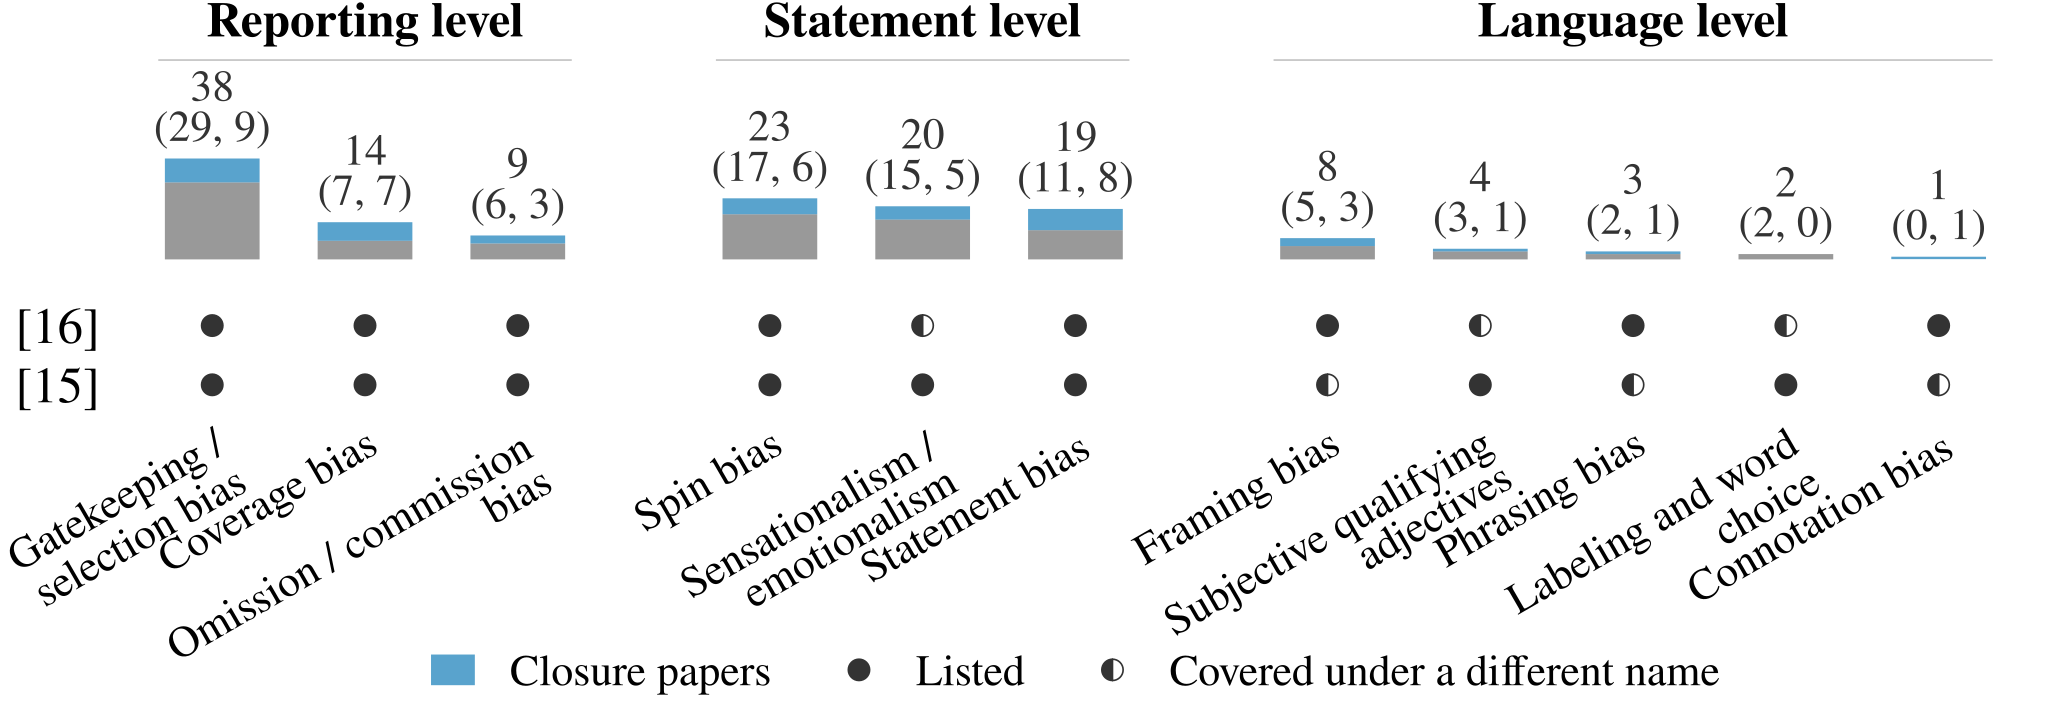

In [3]:
from mbdef.analysis.taxonomy_coverage import run

out = OUTPUTS / "taxonomy-coverage"
report = run(data, gold, out, CONCEPTS)
for row in report["rows"]:
    print(f"{row['concept']:<34} {row['total']:>3} ({row['seed']}, {row['closure']})")
display(SVG(filename=out / "taxonomy_coverage_preview.svg"))

## Review the evidence
`included_papers.csv` has one row per counted type and paper, `matched_records.csv` every matched definition with its status (`included`, `filtered_context`, `manual_exclusion`), `match_log.csv` what each search term found, and `manual_check_*.csv` the definitions of the context-screened types. `taxonomy_source_membership.csv` says whether the taxonomy papers are in MBDef or MBDef-Gold.

In [4]:
print(pl.read_csv(out / "counting_diagnostics.csv"))
print(
    pl.read_csv(out / "taxonomy_source_membership.csv").select(
        "bibkey", "main_corpus_papers", "ground_truth_records"
    )
)

shape: (11, 8)
┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ concept    ┆ included_p ┆ term_match ┆ synonym_o ┆ candidate ┆ context_f ┆ manually_ ┆ context_r │
│ ---        ┆ apers      ┆ ed_papers  ┆ nly_paper ┆ _papers   ┆ iltered_r ┆ excluded_ ┆ equired   │
│ str        ┆ ---        ┆ ---        ┆ s         ┆ ---       ┆ ecords    ┆ records   ┆ ---       │
│            ┆ i64        ┆ i64        ┆ ---       ┆ i64       ┆ ---       ┆ ---       ┆ bool      │
│            ┆            ┆            ┆ i64       ┆           ┆ i64       ┆ i64       ┆           │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ Gatekeepin ┆ 38         ┆ 37         ┆ 1         ┆ 79        ┆ 119       ┆ 0         ┆ true      │
│ g /        ┆            ┆            ┆           ┆           ┆           ┆           ┆           │
│ selection  ┆            ┆            ┆           ┆           ┆           ┆